# Week 2 – Logistics Data Collection, Cleaning and Preprocessing
Yuva Intern | Logistics Data Analyst Project

The working CSV is synthetic (600 simulated shipment records). Public reference: [DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS – Kaggle](https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis). The Kaggle dataset is a domain/field reference only; it is not the working data used here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
path = Path("/content/logistics_shipments_synthetic.csv")
if not path.exists():
    from google.colab import files
    uploaded = files.upload()
    path = Path(next(iter(uploaded)))
df_raw = pd.read_csv(path)
df = df_raw.copy()
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("data_type"))

Saving logistics_shipments_synthetic.csv to logistics_shipments_synthetic.csv
Shape: (600, 14)


,order_id,shipment_id,order_date,warehouse,region,carrier,service_type,planned_distance_km,shipment_weight_kg,dispatch_time,promised_delivery_time,delivered_time,status,actual_cost_inr
0,ORD-0000,SHP-0000,2026-07-08,WH-02,West,Carrier A,Express,127.3,5.1,2026-07-08 10:00:00,2026-07-08 13:08:07.574840772,2026-07-08 13:08:07.574840772,Delivered,240.83
1,ORD-0001,SHP-0001,2026-08-24,WH-03,East,Carrier A,Express,170.0,8.9,2026-08-24 09:00:00,2026-08-24 12:53:23.199370789,NaN,Failed Attempt,368.73
2,ORD-0002,SHP-0002,2026-09-08,WH-03,South,Carrier A,Standard,112.6,12.3,2026-09-08 06:00:00,2026-09-08 07:39:20.290695955,2026-09-08 07:56:52.106701124,Delivered,224.95
3,ORD-0003,SHP-0003,2026-07-25,WH-01,North,Carrier C,Express,101.4,7.5,2026-07-25 17:00:00,2026-07-25 23:07:39.854973989,2026-07-25 21:32:20.633314066,Delivered,187.73
4,ORD-0004,SHP-0004,2026-07-22,WH-02,South,Carrier B,Standard,183.9,6.2,2026-07-22 02:00:00,2026-07-22 07:03:28.988774820,2026-07-22 06:23:53.903282452,Delivered,325.81


,data_type
order_id,object
shipment_id,object
order_date,object
warehouse,object
region,object
carrier,object
service_type,object
planned_distance_km,float64
shipment_weight_kg,float64
dispatch_time,object


## 1. Data collection profile

In [2]:
data_dictionary = pd.DataFrame({
    "column": df.columns,
    "non_null_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "data_type": df.dtypes.astype(str).values,
    "unique_values": df.nunique(dropna=True).values
})
display(data_dictionary)
print("Duplicate shipment IDs:", df["shipment_id"].duplicated().sum())

,column,non_null_count,missing_count,data_type,unique_values
0,order_id,600,0,object,600
1,shipment_id,600,0,object,600
2,order_date,600,0,object,90
3,warehouse,600,0,object,3
4,region,600,0,object,5
5,carrier,595,5,object,3
6,service_type,600,0,object,3
7,planned_distance_km,600,0,float64,530
8,shipment_weight_kg,592,8,float64,296
9,dispatch_time,600,0,object,491


Duplicate shipment IDs: 0


## 2. Data quality assessment

In [3]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean()*100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing_summary)
for col in ["carrier", "region", "service_type", "status"]:
    print("\\n", col)
    display(df[col].value_counts(dropna=False))
date_cols = ["order_date", "dispatch_time", "promised_delivery_time", "delivered_time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")
num_cols = ["planned_distance_km", "shipment_weight_kg", "actual_cost_inr"]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["invalid_time_order"] = (df["delivered_time"].notna() & df["dispatch_time"].notna() &
                            (df["delivered_time"] < df["dispatch_time"]))
df["invalid_distance"] = df["planned_distance_km"] < 0
df["invalid_cost"] = df["actual_cost_inr"] < 0
print("Invalid chronology:", int(df["invalid_time_order"].sum()))
print("Negative distance:", int(df["invalid_distance"].sum()))
print("Negative cost:", int(df["invalid_cost"].sum()))

,missing_count,missing_percent
delivered_time,57,9.50
shipment_weight_kg,8,1.33
carrier,5,0.83
order_date,0,0.00
shipment_id,0,0.00
order_id,0,0.00
region,0,0.00
warehouse,0,0.00
planned_distance_km,0,0.00
service_type,0,0.00


\n carrier


,count
carrier,
Carrier B,203
Carrier C,198
Carrier A,194
NaN,5


\n region


,count
region,
South,135
Central,129
West,122
East,108
North,106


\n service_type


,count
service_type,
Standard,372
Express,174
Same Day,54


\n status


,count
status,
Delivered,543
Failed Attempt,36
In Transit,21


Invalid chronology: 0
Negative distance: 0
Negative cost: 0


## 3. Cleaning: retain raw data, fill missing carrier as Unknown and weight with median. Do not invent delivery timestamps.

In [4]:
df_clean = df.copy()
for col in ["carrier", "region", "service_type", "status", "warehouse"]:
    df_clean[col] = df_clean[col].astype("string").str.strip()
df_clean["carrier"] = df_clean["carrier"].fillna("Unknown")
df_clean["shipment_weight_kg"] = df_clean["shipment_weight_kg"].fillna(
    df_clean["shipment_weight_kg"].median())
df_clean["requires_review"] = (df_clean["invalid_time_order"] |
                               df_clean["invalid_distance"] | df_clean["invalid_cost"])
display(df_clean.isna().sum().to_frame("missing_after_selected_cleaning"))
print("Rows flagged for review:", int(df_clean["requires_review"].sum()))

,missing_after_selected_cleaning
order_id,0
shipment_id,0
order_date,0
warehouse,0
region,0
carrier,0
service_type,0
planned_distance_km,0
shipment_weight_kg,0
dispatch_time,0


Rows flagged for review: 0


## 4. Outlier detection using IQR

In [5]:
def iqr_bounds(series):
    q1, q3 = series.dropna().quantile([0.25, 0.75])
    iqr = q3-q1
    return q1-1.5*iqr, q3+1.5*iqr
outlier_rows=[]
for col in ["planned_distance_km", "shipment_weight_kg", "actual_cost_inr"]:
    low, high = iqr_bounds(df_clean[col])
    df_clean[col+"_outlier"] = (df_clean[col]<low) | (df_clean[col]>high)
    outlier_rows.append({"feature":col,"lower_bound":low,"upper_bound":high,
                         "flagged_count":int(df_clean[col+"_outlier"].sum())})
outlier_summary=pd.DataFrame(outlier_rows)
display(outlier_summary)

,feature,lower_bound,upper_bound,flagged_count
0,planned_distance_km,-81.4625,301.6375,22
1,shipment_weight_kg,-11.9500,40.6500,26
2,actual_cost_inr,-23.7075,514.2725,28


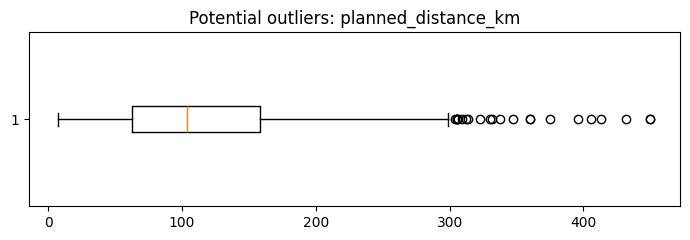

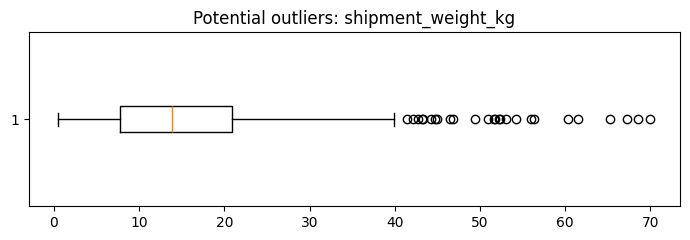

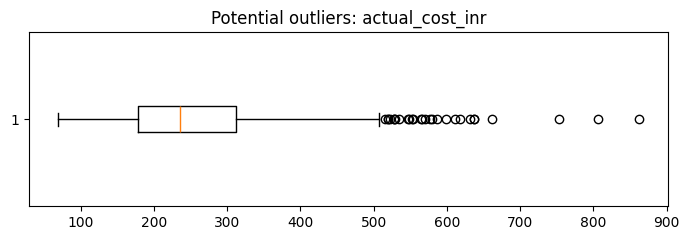

In [6]:
for col in ["planned_distance_km", "shipment_weight_kg", "actual_cost_inr"]:
    plt.figure(figsize=(7,2.5))
    plt.boxplot(df_clean[col].dropna(), vert=False)
    plt.title("Potential outliers: "+col)
    plt.tight_layout()
    plt.show()

## 5. Normalization and standardization
Min-Max maps to 0–1; standardization gives approximately zero mean and unit variance. For modelling, fit scalers on training data only to avoid leakage.

In [7]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
cols=["planned_distance_km","shipment_weight_kg","actual_cost_inr"]
values=df_clean[cols].fillna(df_clean[cols].median())
a=MinMaxScaler().fit_transform(values)
b=StandardScaler().fit_transform(values)
for i,col in enumerate(cols):
    df_clean[col+"_minmax"]=a[:,i]
    df_clean[col+"_standardized"]=b[:,i]
display(df_clean.head())

,order_id,shipment_id,order_date,warehouse,region,carrier,service_type,planned_distance_km,shipment_weight_kg,dispatch_time,...,requires_review,planned_distance_km_outlier,shipment_weight_kg_outlier,actual_cost_inr_outlier,planned_distance_km_minmax,planned_distance_km_standardized,shipment_weight_kg_minmax,shipment_weight_kg_standardized,actual_cost_inr_minmax,actual_cost_inr_standardized
0,ORD-0000,SHP-0000,2026-07-08,WH-02,West,Carrier A,Express,127.3,5.1,2026-07-08 10:00:00,...,False,False,False,False,0.270899,0.106683,0.066187,-0.932050,0.217104,-0.153355
1,ORD-0001,SHP-0001,2026-08-24,WH-03,East,Carrier A,Express,170.0,8.9,2026-08-24 09:00:00,...,False,False,False,False,0.367375,0.652322,0.120863,-0.609840,0.378262,0.938611
2,ORD-0002,SHP-0002,2026-09-08,WH-03,South,Carrier A,Standard,112.6,12.3,2026-09-08 06:00:00,...,False,False,False,False,0.237686,-0.081160,0.169784,-0.321546,0.197094,-0.288933
3,ORD-0003,SHP-0003,2026-07-25,WH-01,North,Carrier C,Express,101.4,7.5,2026-07-25 17:00:00,...,False,False,False,False,0.212381,-0.224278,0.100719,-0.728549,0.150196,-0.606705
4,ORD-0004,SHP-0004,2026-07-22,WH-02,South,Carrier B,Standard,183.9,6.2,2026-07-22 02:00:00,...,False,False,False,False,0.398780,0.829942,0.082014,-0.838779,0.324181,0.572175


## 6. Compare raw and processed data

In [8]:
display(pd.DataFrame({
    "raw_missing_values":df_raw.isna().sum(),
    "processed_missing_values":df_clean.isna().sum()
}))
print("Raw shape:",df_raw.shape,"Processed shape:",df_clean.shape)

,raw_missing_values,processed_missing_values
actual_cost_inr,0.0,0
actual_cost_inr_minmax,NaN,0
actual_cost_inr_outlier,NaN,0
actual_cost_inr_standardized,NaN,0
carrier,5.0,0
delivered_time,57.0,57
dispatch_time,0.0,0
invalid_cost,NaN,0
invalid_distance,NaN,0
invalid_time_order,NaN,0


Raw shape: (600, 14) Processed shape: (600, 27)


## 7. Export processed outputs

In [10]:
out=Path("/content/week2_outputs")
out.mkdir(exist_ok=True)
df_clean.to_csv(out/"logistics_shipments_preprocessed.csv",index=False)
missing_summary.to_csv(out/"missing_value_summary.csv")
outlier_summary.to_csv(out/"outlier_summary.csv",index=False)
data_dictionary.to_csv(out/"data_dictionary.csv",index=False)
print([p.name for p in out.iterdir()])

['outlier_summary.csv', 'missing_value_summary.csv', 'logistics_shipments_preprocessed.csv', 'data_dictionary.csv']


## 8. Conclusion
This notebook demonstrates data profiling, validation, missing-value handling, IQR outlier flags, and numerical scaling. The working data is synthetic. For real operations, repeat the workflow using authorized data and fit transformations on training data only when modelling.